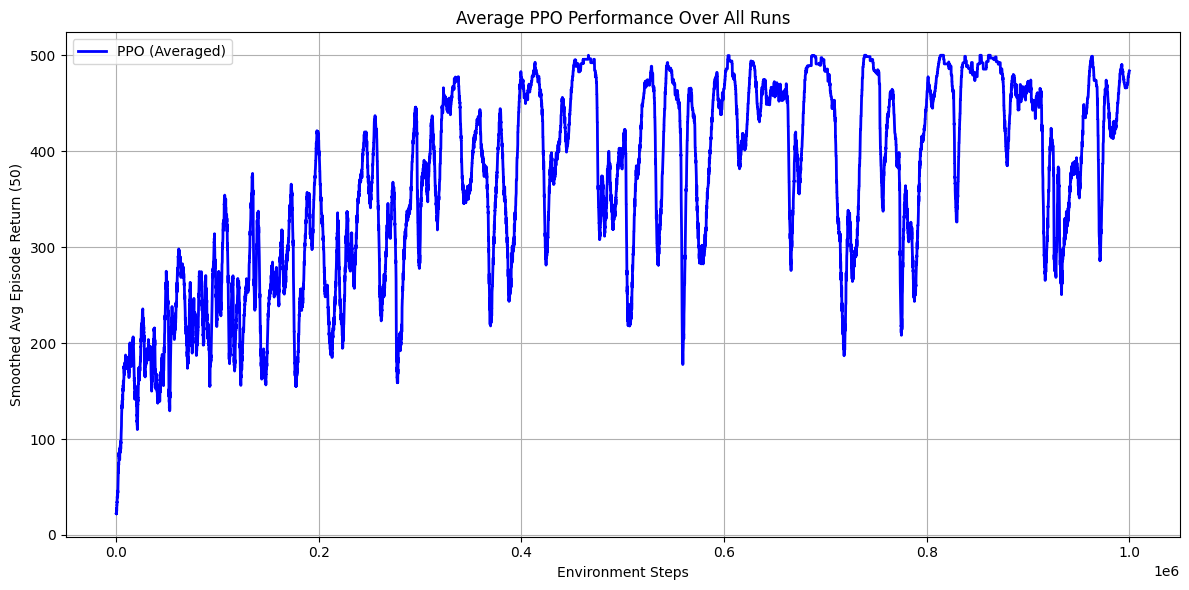

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def moving_average(data, window_size=50):
    return np.convolve(data, np.ones(window_size) / window_size, mode="valid")

df = pd.read_csv("ppo_results_1e6.csv")

required_columns = {"Run", "EnvStep", "EpisodeReturn"}
if not required_columns.issubset(df.columns):
    raise ValueError(f"CSV must contain columns: {required_columns}")

grouped = df.groupby(["EnvStep"])
step_to_returns = grouped["EpisodeReturn"].apply(list)

avg_steps = []
avg_returns = []
for step, returns in step_to_returns.items():
    avg_steps.append(step)
    avg_returns.append(np.mean(returns))

avg_steps, avg_returns = zip(*sorted(zip(avg_steps, avg_returns)))

smoothed_returns = moving_average(avg_returns, window_size=50)
aligned_steps = avg_steps[len(avg_steps) - len(smoothed_returns):]

# Plot
plt.figure(figsize=(12, 6))
plt.plot(aligned_steps, smoothed_returns, label="PPO (Averaged)", color="blue", linewidth=2)
plt.xlabel("Environment Steps")
plt.ylabel("Smoothed Avg Episode Return (50)")
plt.title("Average PPO Performance Over All Runs")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()